# 03 Baseline similarity: examples
This notebook runs the first working `find_similar_products` on the cleaned data and shows what it returns, why, and how it compares with simpler alternatives.

**This is an untuned baseline.** The attribute weights are starting values, and images are not used yet. The engine already has a slot for image embeddings, and tests cover it, but it stays switched off until images are processed.

In [1]:
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from product_similarity.data import canonicalize, load_products
from product_similarity.preprocessing import build_products
from product_similarity.scoring import DEFAULT_WEIGHTS, SimilarityEngine

root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
archive = root / "data" / "archive.zip"
plt.rcParams.update(
    {"figure.figsize": (7, 3.5), "axes.spines.top": False, "axes.spines.right": False}
)
BLUE, GREY, ORANGE = "#4c78a8", "#c7c7c7", "#f58518"
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.width", 170)

rows = load_products(archive)
kept, id_map = canonicalize(rows)
products, _ = build_products(kept)
start = time.perf_counter()
engine = SimilarityEngine(products, id_map)
print(f"Engine built for {len(products):,} products in {time.perf_counter() - start:.1f} s")
by_id = {p.uniq_id: p for p in products}
print("Starting weights (not tuned):", {k: v for k, v in DEFAULT_WEIGHTS.items() if v})

Engine built for 29,529 products in 0.2 s
Starting weights (not tuned): {'title': 0.35, 'category': 0.2, 'brand': 0.1, 'audience': 0.1, 'price': 0.1, 'colour': 0.05, 'weight': 0.05, 'rating': 0.05}


## 1. Five real queries
Four common product types, plus one product with very little data.

In [2]:
rng = random.Random(11)


def pick(category):
    pool = [p for p in products if p.category == category and p.brand and p.price]
    return rng.choice(pool)


queries = [pick(c) for c in ["MensT_Shirts", "WomensKurtasKurtis", "WomensSarees", "BoysT_Shirts"]]
sparse = rng.choice([p for p in products if p.brand is None and p.price is None and p.category])
queries.append(sparse)


def show(product, n=5):
    print(f"QUERY: {product.title[:80]}")
    print(
        f"       category {product.category} | brand {product.brand} | price {product.price} | audience {product.audience}"
    )
    table = []
    for rank, (uid, score) in enumerate(engine.find_similar_with_scores(product.uniq_id, n), 1):
        p = by_id[uid]
        table.append((rank, p.title[:58], p.category, p.brand, p.price, score))
    display(
        pd.DataFrame(
            table, columns=["rank", "title", "category", "brand", "price", "score"]
        ).set_index("rank")
    )


for q in queries:
    show(q)
    print()

QUERY: StormBase Men Skull T-Shirt - Live to Win
       category MensT_Shirts | brand StormBase | price 284.0 | audience men


,title,category,brand,price,score
rank,,,,,
1,StormBase SB Men's V-Neck T-Shirt,MensT_Shirts,StormBase,300.0,0.755269
2,StormBase Run Your Own Race Printed T-Shirt,MensT_Shirts,StormBase,449.0,0.701802
3,Unisopent Mens Skull Printed Full Sleeves T-Shirt,MensT_Shirts,None,299.0,0.631143
4,Urban Age Clothing Co. APNA TIME AAYEGA Men's Round Neck P,MensT_Shirts,None,299.0,0.590659
5,Scott International Men's Bio Wash Cotton V- Neck T-shirt,MensT_Shirts,None,349.0,0.589946



QUERY: Sheknows Fusion Wear Cotton Blue Denim Straight Kurta
       category WomensKurtasKurtis | brand Sheknows | price 720.0 | audience women


,title,category,brand,price,score
rank,,,,,
1,Sheknows Fusion Wear Cotton Blue Denim Straight Kurta,WomensKurtasKurtis,Sheknows,720.0,0.990789
2,Sheknows Fusion Wear Cotton Blue Denim Straight Kurta,WomensKurtasKurtis,Sheknows,738.0,0.988345
3,W for Women's Straight Kurta,WomensKurtasKurtis,None,748.0,0.675963
4,W for Women's Straight Kurta,WomensKurtasKurtis,None,764.0,0.673252
5,W for Women's Straight Kurta,WomensKurtasKurtis,None,679.0,0.671726



QUERY: Craftsvilla Chiffon with Blouse Piece Saree
       category WomensSarees | brand Craftsvilla | price 1179.0 | audience women


,title,category,brand,price,score
rank,,,,,
1,Craftsvilla Silk with Blouse Piece Saree,WomensSarees,Craftsvilla,1169.0,0.929837
2,Craftsvilla Silk with Blouse Piece Saree,WomensSarees,Craftsvilla,1469.0,0.915469
3,Craftsvilla Women's linen Ethnic wear Pink Saree with Blou,WomensSarees,Craftsvilla,1999.0,0.822498
4,Craftsvilla Women's Georgette Saree Blue Color With Blouse,WomensSarees,Craftsvilla,1149.0,0.805054
5,Craftsvilla Women's Poly cotton Traditional Double Zari Bo,WomensSarees,Craftsvilla,1099.0,0.794127



QUERY: Printmate Main Hu PUBG Lover Wala White Graphic Printed Cotton Round Neck Kids B
       category BoysT_Shirts | brand Printmate | price 199.0 | audience boys


,title,category,brand,price,score
rank,,,,,
1,Printmate Love You Dad White Graphic Printed Cotton Round,BoysT_Shirts,Printmate,229.0,0.774069
2,Printmate Love You Grand Pa White Graphic Polyester Round,BoysT_Shirts,Printmate,199.0,0.748957
3,Pepe Jeans Boys Round Neck Printed Tee,BoysT_Shirts,None,220.0,0.616251
4,Pepe Jeans Boys Round Neck Printed Tee,BoysT_Shirts,None,282.0,0.602773
5,US Polo Association Kids Boys' Plain Regular Fit T-Shirt,BoysT_Shirts,None,262.0,0.600440



QUERY: Hanes Men's Blended Brief
       category MensUnderwearBriefs | brand None | price None | audience men


,title,category,brand,price,score
rank,,,,,
1,Hanes Men's Plain Brief,MensUnderwearBriefs,None,199.0,0.869285
2,Hanes Men's Plain Brief,MensUnderwearBriefs,None,167.0,0.865714
3,Hanes Men Casual Brief Pack of 1,MensUnderwearBriefs,None,244.0,0.813315
4,Hanes Men's Cotton Brief (Pack of 2) (Colors May Vary),MensUnderwearBriefs,None,318.0,0.757814
5,Hanes Men's Cotton Brief (Pack of 3) (Colors May Vary),MensUnderwearBriefs,None,717.0,0.743528


### What this shows
Results sit in the same product type and audience as the query, with similar titles and prices. The last query has no brand or price, so it is matched on the attributes it does have, and its scores are less certain.

**Two things to notice.** Several results share an identical title with the query or with each other (for example "W for Women's Straight Kurta" three times, or two Craftsvilla "Silk with Blouse Piece Saree" listings). These are separate listings of what is probably the same item in different sizes or colours, so the top 5 can contain near-copies. Whether to collapse them is tested later.

## 2. Why each product is similar
Each score is a weighted mix, and the breakdown shows each attribute's share of the final score.

Query 1: 'StormBase Men Skull T-Shirt - Live to Win' -> 'StormBase SB Men's V-Neck T-Shirt'
   same category (MensT_Shirts), same audience (men), same brand (StormBase), price 300 vs 284, title match 0.38
   not compared (missing on one side): weight, colour
Query 2: 'Sheknows Fusion Wear Cotton Blue Denim Straig' -> 'Sheknows Fusion Wear Cotton Blue Denim Straig'
   same category (WomensKurtasKurtis), same audience (women), same brand (Sheknows), price 720 vs 720, title match 1.00
   not compared (missing on one side): weight
Query 3: 'Craftsvilla Chiffon with Blouse Piece Saree' -> 'Craftsvilla Silk with Blouse Piece Saree'
   same category (WomensSarees), same audience (women), same brand (Craftsvilla), price 1169 vs 1179, title match 0.84
   not compared (missing on one side): weight, colour
Query 4: 'Printmate Main Hu PUBG Lover Wala White Graph' -> 'Printmate Love You Dad White Graphic Printed '
   same category (BoysT_Shirts), same audience (boys), same brand (Printmate), price 

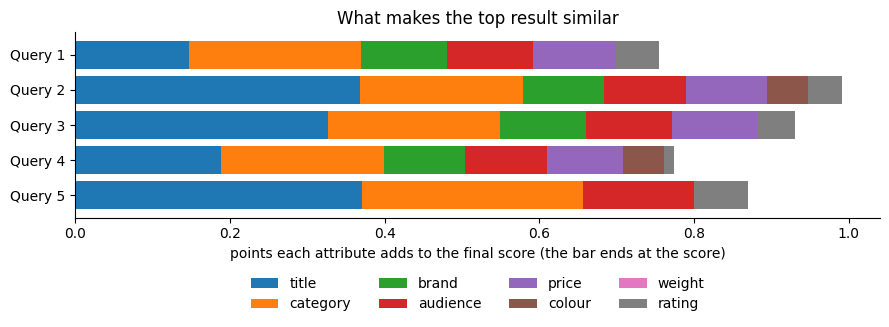

In [3]:
def sentence(q, r, parts):
    bits = []
    if "category" in parts and parts["category"]["similarity"] == 1:
        bits.append(f"same category ({q.category})")
    if "audience" in parts and parts["audience"]["similarity"] == 1:
        bits.append(f"same audience ({q.audience})")
    if "brand" in parts and parts["brand"]["similarity"] == 1:
        bits.append(f"same brand ({q.brand})")
    if "price" in parts:
        bits.append(f"price {r.price:.0f} vs {q.price:.0f}")
    bits.append(f"title match {parts['title']['similarity']:.2f}")
    return ", ".join(bits)


order = ["title", "category", "brand", "audience", "price", "colour", "weight", "rating"]
palette = dict(zip(order, plt.cm.tab10.colors))
fig, ax = plt.subplots(figsize=(9, 3.6))
labels = []
for k, q in enumerate(queries):
    top_id, _ = engine.find_similar_with_scores(q.uniq_id, 1)[0]
    why = engine.explain(q.uniq_id, top_id)
    print(f"Query {k + 1}: '{q.title[:45]}' -> '{by_id[top_id].title[:45]}'")
    print(f"   {sentence(q, by_id[top_id], why['attributes'])}")
    if why["skipped"]:
        print(f"   not compared (missing on one side): {', '.join(why['skipped'])}")
    left = 0.0
    for name in order:
        share = why["attributes"].get(name, {}).get("share", 0.0)
        ax.barh(k, share, left=left, color=palette[name], label=name if k == 0 else None)
        left += share
    labels.append(f"Query {k + 1}")
ax.set_yticks(range(len(queries)))
ax.set_yticklabels(labels)
ax.invert_yaxis()
ax.set_xlabel("points each attribute adds to the final score (the bar ends at the score)")
ax.set_title("What makes the top result similar")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.25), frameon=False)
plt.tight_layout()
plt.show()

### What this shows
For most queries, title, category and audience make up most of the score, as designed. For the query with little data, the score comes mostly from the title and category, because the missing attributes are skipped and the remaining weights are rescaled.

## 3. Speed

300 random queries for the top 10: median 5.9 ms, 95th percentile 6.7 ms, slowest 7.3 ms


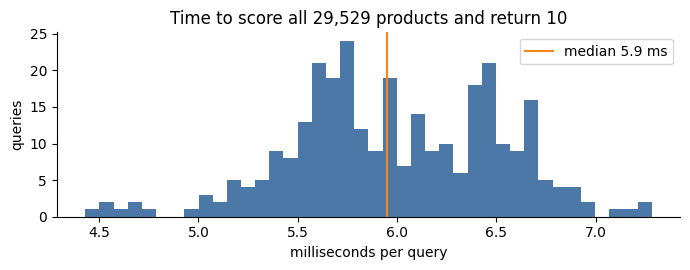

In [4]:
rng = random.Random(7)
sample = [p.uniq_id for p in rng.sample(products, 300)]
times = []
for uid in sample:
    t = time.perf_counter()
    engine.find_similar(uid, 10)
    times.append((time.perf_counter() - t) * 1000)
print(
    f"300 random queries for the top 10: median {np.median(times):.1f} ms, 95th percentile {np.percentile(times, 95):.1f} ms, slowest {max(times):.1f} ms"
)
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.hist(times, bins=40, color=BLUE)
ax.axvline(np.median(times), color=ORANGE, label=f"median {np.median(times):.1f} ms")
ax.set_xlabel("milliseconds per query")
ax.set_ylabel("queries")
ax.legend()
ax.set_title("Time to score all 29,529 products and return 10")
plt.tight_layout()
plt.show()

### What this shows
Scoring every product exactly takes a few milliseconds on this laptop, so for 30,000 products no approximate search is needed to be fast. The fast-search experiments in a later stage test whether it still pays off, and at what size.

## 4. Comparison with simple alternatives
Same 200 random queries, four methods. There are no human-labelled answers yet, so this shows how the methods *behave*, not which one is best.

,same category,same audience,identical title,overlap with baseline,ms per query
Baseline (title + attributes),0.95,0.98,0.15,1.00,6.02
Title only,0.67,0.86,0.16,0.51,4.24
Attributes only (no title),0.89,0.96,0.02,0.18,5.86
Random,0.05,0.34,0.00,0.00,NaN


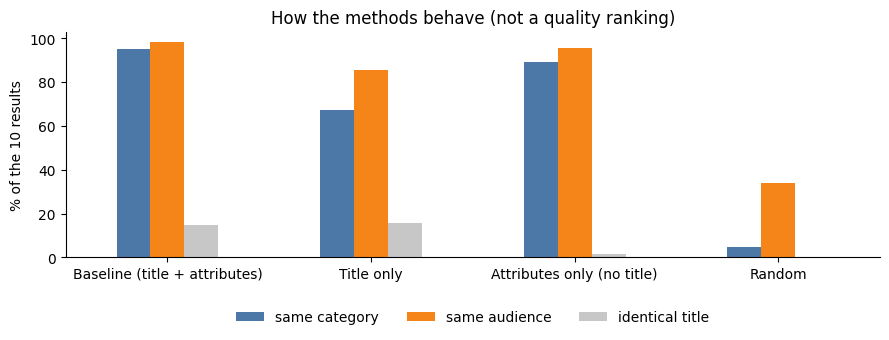

In [5]:
zero = dict.fromkeys(DEFAULT_WEIGHTS, 0.0)
engines = {
    "Baseline (title + attributes)": engine,
    "Title only": SimilarityEngine(products, id_map, {**zero, "title": 1.0}),
    "Attributes only (no title)": SimilarityEngine(products, id_map, {"title": 0.0}),
}
rng = random.Random(5)
queries200 = [p.uniq_id for p in rng.sample(products, 200)]
results = {name: [e.find_similar(q, 10) for q in queries200] for name, e in engines.items()}
all_ids = [p.uniq_id for p in products]
results["Random"] = [rng.sample(all_ids, 10) for _ in queries200]


def same_category(a, b):
    return a.category is not None and a.category == b.category


def same_audience(a, b):
    return a.audience is not None and a.audience == b.audience


def same_title(a, b):
    return a.title == b.title


table = []
base_lists = results["Baseline (title + attributes)"]
for name, res in results.items():
    row = {}
    for label, test in [
        ("same category", same_category),
        ("same audience", same_audience),
        ("identical title", same_title),
    ]:
        row[label] = np.mean(
            [
                np.mean([test(by_id[engine.ids[engine.resolve(q)]], by_id[r]) for r in rs])
                for q, rs in zip(queries200, res)
            ]
        )
    row["overlap with baseline"] = np.mean(
        [len(set(r) & set(b)) / 10 for r, b in zip(res, base_lists)]
    )
    e = engines.get(name)
    if e is not None:
        t = time.perf_counter()
        for q in queries200[:50]:
            e.find_similar(q, 10)
        row["ms per query"] = (time.perf_counter() - t) / 50 * 1000
    table.append(pd.Series(row, name=name))
comparison = pd.DataFrame(table)
display(comparison.round(2))

ax = (
    comparison[["same category", "same audience", "identical title"]]
    .mul(100)
    .plot.bar(figsize=(9, 3.6), rot=0, color=[BLUE, ORANGE, GREY])
)
ax.set_ylabel("% of the 10 results")
ax.set_title("How the methods behave (not a quality ranking)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3, frameon=False)
plt.tight_layout()
plt.show()

### What this shows, and what it does not
- **Random** almost never returns the same category (about 5%), so the other methods are clearly doing something real.
- **Title only** finds products with similar words but often from a different category or audience, and it returns about as many identical-title copies as the baseline.
- **Attributes only** keeps category and audience but rarely returns identical titles, so it finds more varied products. Its results overlap little with the baseline's, so the title makes a large difference.
- **The baseline** sits between them and returns the most same-category, same-audience results.

**Caution:** category and audience are used in the baseline's scoring, so its high same-category share is partly built in. It is not independent proof of quality. Which method is better will be decided in Stage 2 onward with a set of judged examples. This table only shows that the choices change the results a lot.

**A weakness in the missing-data rule.** In the attributes-only list above, the top products score a perfect 1.000 even though many of them have no price. When an attribute is missing it is skipped, so a product that can only be compared on category and audience can look like a perfect match. This is the known risk of rescaling the weights. A penalty for products with little data is tested later.

## 5. The same query, three methods

In [6]:
q = queries[0]
print(f"QUERY: {q.title}")
for name in ["Baseline (title + attributes)", "Title only", "Attributes only (no title)"]:
    print(f"\n{name}")
    for uid, score in engines[name].find_similar_with_scores(q.uniq_id, 5):
        p = by_id[uid]
        print(f"  {score:.3f}  {p.title[:62]}  [{p.category}, {p.price}]")

QUERY: StormBase Men Skull T-Shirt - Live to Win

Baseline (title + attributes)
  0.755  StormBase SB Men's V-Neck T-Shirt  [MensT_Shirts, 300.0]
  0.702  StormBase Run Your Own Race Printed T-Shirt  [MensT_Shirts, 449.0]
  0.631  Unisopent Mens Skull Printed Full Sleeves T-Shirt  [MensT_Shirts, 299.0]
  0.591  Urban Age Clothing Co. APNA TIME AAYEGA Men's Round Neck Print  [MensT_Shirts, 299.0]
  0.590  Scott International Men's Bio Wash Cotton V- Neck T-shirt (Bla  [MensT_Shirts, 349.0]

Title only
  0.377  StormBase SB Men's V-Neck T-Shirt  [MensT_Shirts, 300.0]
  0.250  StormBase Run Your Own Race Printed T-Shirt  [MensT_Shirts, 449.0]
  0.219  Print Vale Live Like a King Funny Design Printed 100% Cotton W  [MensT_Shirts, 399.0]
  0.210  U.S.Polo Association Men's Skull Cap  [MensCapsHats, 479.0]
  0.202  Black & White Skull Beanie  [MensCapsHats, None]

Attributes only (no title)
  1.000  Hanes Men's 3-Pack Tagless Crew Neck T-Shirt  [MensT_Shirts, None]
  1.000  Adidas Men's Poly

## 6. Correctness checks on the real data

In [7]:
rng = random.Random(21)
raw_ids = rng.sample(sorted(id_map), 200)
checks = {"every original ID resolves": all(engine.resolve(uid) is not None for uid in id_map)}
ok_excl = ok_unique = ok_sorted = ok_repeat = True
for uid in raw_ids:
    ranked = engine.find_similar_with_scores(uid, 10)
    ids = [r for r, _ in ranked]
    scores = [s for _, s in ranked]
    ok_excl &= id_map[uid] not in ids and uid not in ids
    ok_unique &= len(set(ids)) == len(ids) == 10
    ok_sorted &= scores == sorted(scores, reverse=True)
    ok_repeat &= engine.find_similar(uid, 10) == engine.find_similar(id_map[uid], 10)
checks["query never returned (200 queries)"] = ok_excl
checks["no product listed twice (200 queries)"] = ok_unique
checks["scores sorted from best to worst (200 queries)"] = ok_sorted
checks["an old repeated ID gives the kept product's results"] = ok_repeat
checks["same query twice gives the same list"] = engine.find_similar(
    raw_ids[0], 10
) == engine.find_similar(raw_ids[0], 10)
checks["asking for more than exist returns all others"] = (
    len(engine.find_similar(raw_ids[0], 10**6)) == len(products) - 1
)
display(pd.Series(checks, name="passed").to_frame())
assert all(checks.values())

,passed
every original ID resolves,True
query never returned (200 queries),True
no product listed twice (200 queries),True
scores sorted from best to worst (200 queries),True
an old repeated ID gives the kept product's results,True
same query twice gives the same list,True
asking for more than exist returns all others,True


## 7. Conclusion

**Goal:** build a first working "find similar products" function on the cleaned data, and show what it returns and why. It is an **untuned baseline**: the weights are starting values, and images are not used yet.

**1. How it finds similar products**
- **What I did:** compared the product with every other product on title, category, brand, audience, price, colour, weight and rating. Each gets a score from 0 to 1, and a weighted average gives the final score. The best scores are returned.
- **Example:** for "StormBase Men Skull T-Shirt", the top result is another StormBase men's T-shirt in the same category, at a similar price (300 vs 284).
- **Why:** the results are the same type of product, for the same audience, at a similar price.

In [8]:
top = []
for q in queries:
    uid, score = engine.find_similar_with_scores(q.uniq_id, 1)[0]
    top.append((q.title[:45], by_id[uid].title[:45], by_id[uid].price, score))
display(pd.DataFrame(top, columns=["query", "top result", "price of result", "score"]))

,query,top result,price of result,score
0,StormBase Men Skull T-Shirt - Live to Win,StormBase SB Men's V-Neck T-Shirt,300.0,0.755269
1,Sheknows Fusion Wear Cotton Blue Denim Straig,Sheknows Fusion Wear Cotton Blue Denim Straig,720.0,0.990789
2,Craftsvilla Chiffon with Blouse Piece Saree,Craftsvilla Silk with Blouse Piece Saree,1169.0,0.929837
3,Printmate Main Hu PUBG Lover Wala White Graph,Printmate Love You Dad White Graphic Printed,229.0,0.774069
4,Hanes Men's Blended Brief,Hanes Men's Plain Brief,199.0,0.869285


**2. Why each result is similar**
- **What I did:** for every result, the notebook shows what each attribute added to the score.
- **Example:** one top result is "same category, same audience, same brand, price 300 vs 284, title match 0.38".
- **Why:** so any result can be explained, not just trusted.

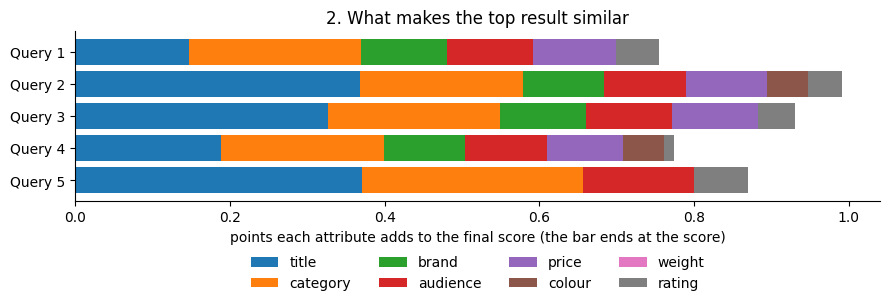

In [9]:
fig, ax = plt.subplots(figsize=(9, 3.4))
for k, q in enumerate(queries):
    top_id, _ = engine.find_similar_with_scores(q.uniq_id, 1)[0]
    why = engine.explain(q.uniq_id, top_id)
    left = 0.0
    for name in order:
        share = why["attributes"].get(name, {}).get("share", 0.0)
        ax.barh(k, share, left=left, color=palette[name], label=name if k == 0 else None)
        left += share
ax.set_yticks(range(len(queries)))
ax.set_yticklabels([f"Query {k + 1}" for k in range(len(queries))])
ax.invert_yaxis()
ax.set_xlabel("points each attribute adds to the final score (the bar ends at the score)")
ax.set_title("2. What makes the top result similar")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.25), frameon=False)
plt.tight_layout()
plt.show()

**3. Missing information is skipped, not guessed**
- **What I did:** if either product lacks an attribute, that attribute is skipped and the rest are rescaled.
- **Example:** "Hanes Men's Blended Brief" has no brand or price, so it is matched on title, category and audience only.
- **Why:** nothing is made up.

,query,attributes compared (of 8),skipped
0,Query 1,6,"weight, colour"
1,Query 2,7,weight
2,Query 3,6,"weight, colour"
3,Query 4,7,weight
4,Query 5,4,"brand, price, weight, colour"


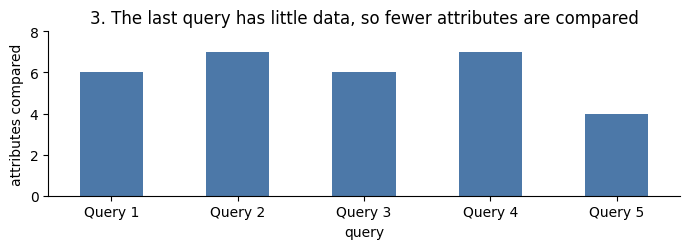

In [10]:
rows_used = []
for k, q in enumerate(queries):
    top_id, _ = engine.find_similar_with_scores(q.uniq_id, 1)[0]
    why = engine.explain(q.uniq_id, top_id)
    rows_used.append(
        (f"Query {k + 1}", len(why["attributes"]), ", ".join(why["skipped"]) or "none")
    )
used = pd.DataFrame(rows_used, columns=["query", "attributes compared (of 8)", "skipped"])
display(used)
ax = used.set_index("query")["attributes compared (of 8)"].plot.bar(
    color=BLUE, rot=0, figsize=(7, 2.6)
)
ax.set_ylim(0, 8)
ax.set_ylabel("attributes compared")
ax.set_title("3. The last query has little data, so fewer attributes are compared")
plt.tight_layout()
plt.show()

**4. Speed**
- **What I did:** timed 300 random queries that score all 29,529 products.
- **Result:** a median of 6 ms (95th percentile under 7 ms), and the engine builds in under a second.
- **Why:** exact scoring is already fast at this size, so fast approximate search will be tested later to see if it helps.

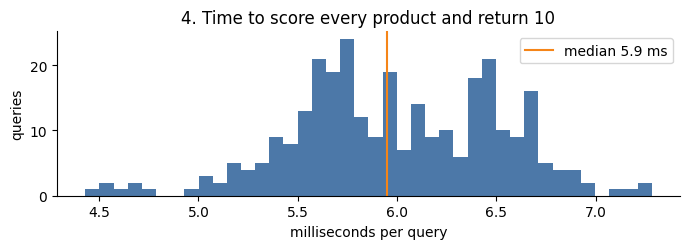

In [11]:
fig, ax = plt.subplots(figsize=(7, 2.6))
ax.hist(times, bins=40, color=BLUE)
ax.axvline(np.median(times), color=ORANGE, label=f"median {np.median(times):.1f} ms")
ax.set_xlabel("milliseconds per query")
ax.set_ylabel("queries")
ax.legend()
ax.set_title("4. Time to score every product and return 10")
plt.tight_layout()
plt.show()

**5. Comparison with simple alternatives**
- **What I did:** ran the same 200 queries with four methods.
- **Result:** the methods return very different lists. Random almost never matches the category (5%), title-only matches it 67% of the time, attributes-only 89%, and the baseline 95%.
- **Why it matters, and its limit:** it shows the choices change the results a lot. It does **not** show which method is best, because there are no judged answers yet, and the baseline's category score is partly built in.

,same category,same audience,identical title,overlap with baseline,ms per query
Baseline (title + attributes),0.95,0.98,0.15,1.00,6.02
Title only,0.67,0.86,0.16,0.51,4.24
Attributes only (no title),0.89,0.96,0.02,0.18,5.86
Random,0.05,0.34,0.00,0.00,NaN


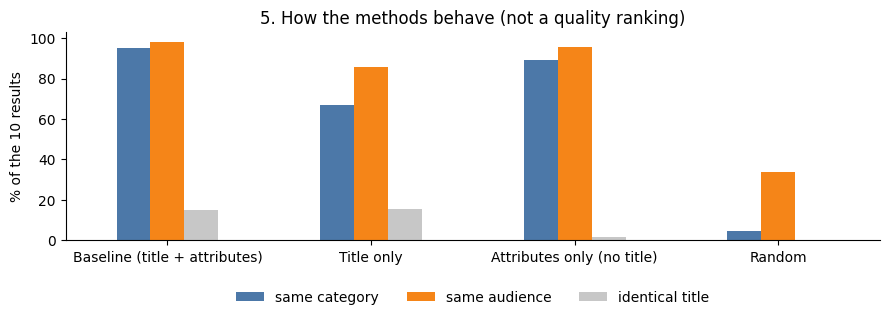

In [12]:
display(comparison.round(2))
ax = (
    comparison[["same category", "same audience", "identical title"]]
    .mul(100)
    .plot.bar(figsize=(9, 3.4), rot=0, color=[BLUE, ORANGE, GREY])
)
ax.set_ylabel("% of the 10 results")
ax.set_title("5. How the methods behave (not a quality ranking)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3, frameon=False)
plt.tight_layout()
plt.show()

**6. Checks on the real data**
- **What I did:** ran 200 real queries and checked the rules.
- **Result:** the query is never returned, no product appears twice, scores are in order, an old repeated ID gives the kept product's results, and the same query gives the same list.
- **Why:** so the function behaves correctly.

,passed
every original ID resolves,True
query never returned (200 queries),True
no product listed twice (200 queries),True
scores sorted from best to worst (200 queries),True
an old repeated ID gives the kept product's results,True
same query twice gives the same list,True
asking for more than exist returns all others,True


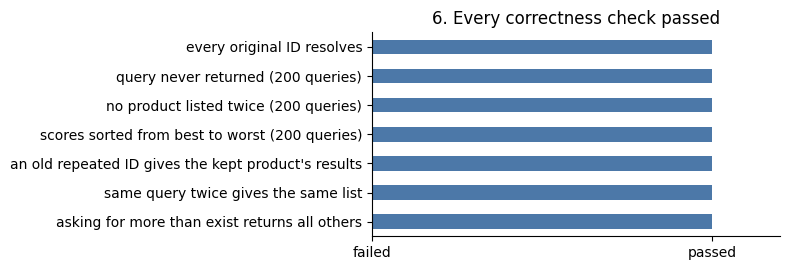

In [13]:
display(pd.Series(checks, name="passed").to_frame())
ax = (
    pd.Series({k: int(v) for k, v in checks.items()})
    .iloc[::-1]
    .plot.barh(color=BLUE, figsize=(8, 2.8))
)
ax.set_xlim(0, 1.2)
ax.set_xticks([0, 1])
ax.set_xticklabels(["failed", "passed"])
ax.set_title("6. Every correctness check passed")
plt.tight_layout()
plt.show()

**What I found that needs work**
- **Near-copies:** for a kurta query, "W for Women's Straight Kurta" appears three times in the top 5, because the same item is listed several times. Whether to merge them is tested later.
- **Over-scored sparse products:** a product with very little data can score a perfect 1.000 when only category and audience were compared. A penalty for little data is tested later.

**Overall:** the baseline already gives sensible, explainable results, fast. It is not yet tuned: weights, images and these two weaknesses are the next things to test.

**Next:** build the web service and Docker image, so anyone can call it with a web link.